In [1]:
import sys
sys.path.insert(0, r"C:\Users\mgluszynski\Programowanie\src")

In [2]:
import random
import statistics
import matplotlib.pyplot as plt

from species import Prey, Predator
from prey_predator import Population

In [3]:
def run_once(seed: int, steps: int = 150, plot: bool = False,
             overrides: dict | None = None) -> Population:
    """Uruchamia jedną symulację z danym ziarnem i opcjonalnymi nadpisaniami."""
    random.seed(seed)
    if overrides:
        for cls, params in overrides.items():
            for k, v in params.items():
                setattr(cls, k, v)
    pop = Population({Prey: 90, Predator: 30})
    for _ in range(steps):
        pop.natural_selection()
    if plot:
        pop.plot_history()
    return pop

In [4]:
def base_experiment(n_reps: int = 10, steps: int = 150):
    prey_ext = 0
    pred_ext = 0
    final_prey, final_pred = [], []
    for seed in range(n_reps):
        pop = run_once(seed, steps)
        h = pop.history[-1]
        final_prey.append(h.prey)
        final_pred.append(h.predators)
        if h.prey == 0:
            prey_ext += 1
        if h.predators == 0:
            pred_ext += 1

    print("Eksperyment bazowy")
    print(f"Powtórzenia: {n_reps}, kroki: {steps}")
    print(f"% wymarcia ofiar:     {100*prey_ext/n_reps:.1f}%")
    print(f"% wymarcia drapieżców: {100*pred_ext/n_reps:.1f}%")
    print(f"Końcowa liczebność ofiar:     "
          f"średnia={statistics.mean(final_prey):.2f}, "
          f"odch.={statistics.pstdev(final_prey):.2f}")
    print(f"Końcowa liczebność drapieżców: "
          f"średnia={statistics.mean(final_pred):.2f}, "
          f"odch.={statistics.pstdev(final_pred):.2f}")

In [5]:
def sensitivity_experiment(n_reps: int = 10, steps: int = 150):
    scenarios = [
        ("Prey.p_reproduce=0.3", {Prey: {"p_reproduce": 0.3}}),
        ("Prey.p_reproduce=0.5", {Prey: {"p_reproduce": 0.5}}),
        ("Prey.p_reproduce=0.7", {Prey: {"p_reproduce": 0.7}}),
        ("Predator.p_death=0.05", {Predator: {"p_death": 0.05}}),
        ("Predator.p_death=0.10", {Predator: {"p_death": 0.10}}),
        ("Predator.p_death=0.20", {Predator: {"p_death": 0.20}}),
    ]
    print("=== Analiza wrażliwości ===")
    for label, overrides in scenarios:
        # zapamiętaj stare wartości
        old = {cls: {k: getattr(cls, k) for k in params}
               for cls, params in overrides.items()}
        try:
            prey_ext = pred_ext = 0
            fp, fd = [], []
            for seed in range(n_reps):
                pop = run_once(seed, steps, overrides=overrides)
                h = pop.history[-1]
                fp.append(h.prey)
                fd.append(h.predators)
                prey_ext += (h.prey == 0)
                pred_ext += (h.predators == 0)
            print(f"\n-- {label} --")
            print(f"  % wymarcia ofiar:     {100*prey_ext/n_reps:.1f}%")
            print(f"  % wymarcia drapieżców: {100*pred_ext/n_reps:.1f}%")
            print(f"  Ofiary:     μ={statistics.mean(fp):.2f}, "
                  f"σ={statistics.pstdev(fp):.2f}")
            print(f"  Drapieżcy:  μ={statistics.mean(fd):.2f}, "
                  f"σ={statistics.pstdev(fd):.2f}")
        finally:
            # przywróć stare wartości – nawet jeśli coś padnie
            for cls, params in old.items():
                for k, v in params.items():
                    setattr(cls, k, v)

In [6]:
def histogram_experiment(seed: int = 0, steps: int = 150,
                         attr: str = "p_reproduce"):
    pop = run_once(seed, steps)
    pop.plot_histogram(attr)


Zadanie 2/3: przebieg bazowy, ziarno=42


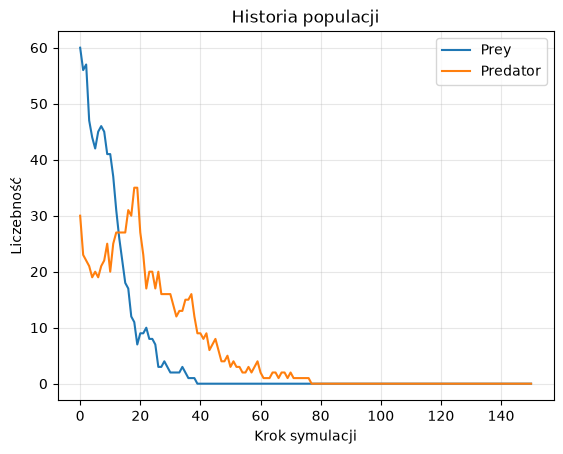

In [ ]:
if __name__ == "__main__":
    # Zadanie 2 & 3 – przebieg bazowy z wykresem
    print("Zadanie 2/3: przebieg bazowy, ziarno=42")
    run_once(seed=42, steps=150, plot=True)

    # Zadanie 3 – weryfikacja powtarzalności
    p1 = run_once(seed=42, steps=150)
    p2 = run_once(seed=42, steps=150)
    print("Powtarzalność (to samo ziarno):",
          p1.history[-1] == p2.history[-1])

    # Zadanie 4 
    base_experiment(n_reps=10, steps=150)

    # Zadanie 5 
    sensitivity_experiment(n_reps=10, steps=150)

    # Zadanie 6 
    histogram_experiment(seed=42, steps=150, attr="p_reproduce")